['culture', 'technology', 'science', 'business', 'TEDx', 'global issues', 'entertainment', 'design', 'psychology', 'brain']


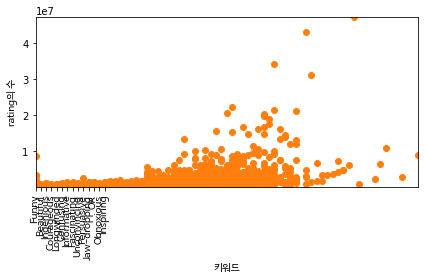

In [10]:
import csv
import json
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from operator import itemgetter


def preprocess_talks(csv_file):
    '''
    주어진 CSV 파일을 열어 처리 가능한 파이썬의 리스트 형태로 변환합니다.
    리스트의 각 원소는 문제에서 설명된 딕셔너리 형태로 이루어져 있습니다.
    '''
    # 강연 데이터를 저장할 리스트
    talks = []

    # CSV 파일을 열고, 데이터를 읽어 와서 talks에 저장합니다.
    with open(csv_file) as file:
        reader = csv.reader(file, delimiter=',')

        for row in reader:
            try:
                talk = {
                    'title': row[14],
                    'speaker': row[6],
                    'views': int(row[16]),
                    'comments': int(row[0]),
                    'duration': int(row[2]),
                    'languages': int(row[5]),
                    'tags': json.loads(row[13].replace("'", '"')),
                    'ratings': json.loads(row[10].replace("'", '"')),
                }
            except:
                pass
            talks.append(talk)

    return talks


def get_popular_tags(talks, n):
    '''
    가장 인기 있는 태그 상위 n개를 리턴합니다.
    태그의 인기도는 해당 태그를 포함하는 강의들의 조회수 합으로 결정됩니다.
    예를 들어, 'education' 태그가 포함된 강의가 총 15개라면
    'education' 태그의 인기도는 이 15개 강의의 조회수 총합입니다.
    '''
    # 태그 별 인기도를 저장할 딕셔너리
    tag_to_views = {}

    # 태그 별 인기도를 구해 tag_to_views에 저장합니다.
    for talk in talks:
        tags, views = talk['tags'], talk['views']
        for tag in tags:
            if tag in tag_to_views:
                tag_to_views[tag] += views
            else:
                tag_to_views[tag] = views

    # (태그, 인기도)의 리스트 형식으로 변환합니다.
    tag_view_pairs = list(tag_to_views.items())

    # 인기도가 높은 순서로 정렬해 앞의 n개를 취합니다.
    # n개를 취한 후에는 태그만 남깁니다.
    # 힌트: itemgetter()를 사용하세요!
    top_tag_and_views = sorted(
        tag_view_pairs, key=itemgetter(1), reverse=True)[:n]
    top_tags = map(itemgetter(0), top_tag_and_views)

    return list(top_tags)


def completion_rate_by_duration(talks):
    '''
    강의 길이에 따라 강의를 끝까지 들은 비율이 어떻게 변화하는지 확인해 봅니다.
    강의를 끝까지 들은 비율은 (댓글 개수 / 조회수)에 비례한다고 가정합니다.
    '''
    completion_rates = [talk['comments'] / talk['views'] for talk in talks]
    durations = [talk['duration'] for talk in talks]
    scatter_plot(durations, completion_rates, '강의 길이', '완수도')

    # 채점을 위해 결과를 리턴합니다.
    return completion_rates, durations


def views_by_languages(talks):
    '''
    지원되는 언어의 수에 따라 조회수가 어떻게 변화하는지 확인해 봅니다.
    '''
    languages = [talk['languages'] for talk in talks]
    views = [talk['views'] for talk in talks]
    scatter_plot(languages, views, '언어의 수', '조회수')

    # 채점을 위해 결과를 리턴합니다.
    return views, languages


def show_ratings(talk):
    '''
    강의에 대한 다양한 평가(rating)를 막대그래프로 표현합니다.
    각 키워드('fun', 'confusing' 등)별 숫자를 나타냅니다. 
    '''
    ratings = talk['ratings']
    keywords = [rating['name'] for rating in ratings]
    counts = [rating['count'] for rating in ratings]
    bar_plot(keywords, counts, '키워드', 'rating의 수')

    # 채점을 위해 결과를 리턴합니다.
    return keywords, counts


def scatter_plot(x, y, x_label, y_label):
    '''
    x, y 데이터를 이용하여 scatter plot을 그립니다.
    '''
    font = fm.FontProperties(fname='./NanumBarunGothic.ttf')

    plt.scatter(x, y)
    plt.xlabel(x_label, fontproperties=font)
    plt.ylabel(y_label, fontproperties=font)

    plt.xlim((min(x), max(x)))
    plt.ylim((min(y), max(y)))
    plt.tight_layout()


def bar_plot(x_ticks, y, x_label, y_label):
    '''
    막대그래프를 그립니다.
    막대의 높이 데이터인 y와 각 막대에 대한 설명인 x_ticks를 인자로 받습니다.
    '''
    # x_ticks와 y의 길이가 같은지 확인합니다. 아니라면 에러가 발생합니다.
    assert(len(x_ticks) == len(y))

    font = fm.FontProperties(fname='./NanumBarunGothic.ttf')

    pos = range(len(y))
    plt.bar(pos, y, align='center')
    plt.xticks(pos, x_ticks, rotation='vertical', fontproperties=font)

    plt.xlabel(x_label, fontproperties=font)
    plt.ylabel(y_label, fontproperties=font)
    plt.tight_layout()


def main():
    src = 'ted.csv'
    talks = preprocess_talks(src)
    print(get_popular_tags(talks, 10))
    completion_rate_by_duration(talks)
    views_by_languages(talks)
    show_ratings(talks[0])


if __name__ == "__main__":
    main()
